In [2]:
import pandas as pd, numpy as np, re, os
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# File enga irukkunu auto-ah kandupidikkum
PATH = '/content/spam_sms.csv' if os.path.exists('/content/spam_sms.csv') else '/spam_sms.csv'
print("File found:", os.path.exists(PATH), "->", PATH)

File found: True -> /content/spam_sms.csv


In [3]:
df = pd.read_csv(PATH, encoding='latin-1')
df = df[['v1', 'v2']]
df.columns = ['label', 'text']

print("Original shape:", df.shape)
print("Missing values:\n", df.isnull().sum())

df = df.dropna()
df = df.drop_duplicates()

df, _ = train_test_split(df, train_size=2000, stratify=df['label'], random_state=42)
df = df.reset_index(drop=True)

print("\nSubset shape:", df.shape)
print(df['label'].value_counts())
df.head()

Original shape: (5572, 2)
Missing values:
 label    0
text     0
dtype: int64

Subset shape: (2000, 2)
label
ham     1747
spam     253
Name: count, dtype: int64


,label,text
0,spam,"500 New Mobiles from 2004, MUST GO! Txt: NOKIA..."
1,ham,Are you this much buzy
2,ham,"ItÂÃÃ·s Ã¥Â£6 to get in, is that ok?"
3,ham,Aiyah sorry lor... I watch tv watch until i fo...
4,ham,Kinda. First one gets in at twelve! Aah. Speak...


In [4]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r'http\S+|www\S+', ' url ', t)
    t = re.sub(r'\d+', ' num ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df['clean'] = df['text'].apply(clean_text)
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

df[['text', 'clean', 'target']].head()

,text,clean,target
0,"500 New Mobiles from 2004, MUST GO! Txt: NOKIA...",num new mobiles from num must go txt nokia to ...,1
1,Are you this much buzy,are you this much buzy,0
2,"ItÂÃÃ·s Ã¥Â£6 to get in, is that ok?",it s num to get in is that ok,0
3,Aiyah sorry lor... I watch tv watch until i fo...,aiyah sorry lor i watch tv watch until i forgo...,0
4,Kinda. First one gets in at twelve! Aah. Speak...,kinda first one gets in at twelve aah speak tomo,0


In [5]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df['clean'], df['target'], test_size=0.2,
    stratify=df['target'], random_state=42)

VOCAB_SIZE = 5000
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_txt)

X_train_seq = tokenizer.texts_to_sequences(X_train_txt)
X_test_seq  = tokenizer.texts_to_sequences(X_test_txt)

MAX_LEN = 50
X_train = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test  = pad_sequences(X_test_seq,  maxlen=MAX_LEN, padding='post', truncating='post')

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Sample text     :", X_train_txt.iloc[0])
print("Sample sequence :", X_train[0])

Train shape: (1600, 50)  Test shape: (400, 50)
Sample text     : hi dude hw r u da realy mising u today
Sample sequence : [  85  428 1156  103    8  100 1157 1725    8   93    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


In [11]:
tf.keras.utils.set_random_seed(42)   # same result varum

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=32),
    GRU(64),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.build(input_shape=(None, MAX_LEN))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 180,929 (706.75 KB)

 Trainable params: 180,929 (706.75 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=32,
                    validation_split=0.1,
                    callbacks=[es], verbose=1)

Epoch 1/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.8569 - loss: 0.4853 - val_accuracy: 0.8938 - val_loss: 0.3492
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8715 - loss: 0.3909 - val_accuracy: 0.8938 - val_loss: 0.3394
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8715 - loss: 0.3882 - val_accuracy: 0.8938 - val_loss: 0.3361
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8715 - loss: 0.3721 - val_accuracy: 0.8938 - val_loss: 0.3042
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9104 - loss: 0.2497 - val_accuracy: 0.9750 - val_loss: 0.1095
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9785 - loss: 0.0896 - val_accuracy: 0.9750 - val_loss: 0.0699
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9889 - loss: 0.0427 - val_accuracy: 0.9812 - val_loss: 0.0662
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9937 - loss: 0.0261 - val_accuracy: 0.9812 - v

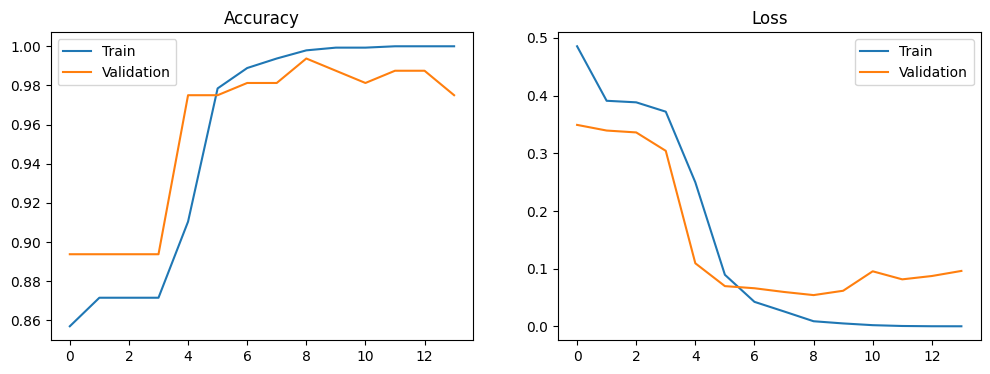

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['accuracy'], label='Train')
ax[0].plot(history.history['val_accuracy'], label='Validation')
ax[0].set_title('Accuracy'); ax[0].legend()
ax[1].plot(history.history['loss'], label='Train')
ax[1].plot(history.history['val_loss'], label='Validation')
ax[1].set_title('Loss'); ax[1].legend()
plt.show()

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Accuracy  : 0.9825
Precision : 0.9231
Recall    : 0.9412
F1-score  : 0.932

               precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       349
        Spam       0.92      0.94      0.93        51

    accuracy                           0.98       400
   macro avg       0.96      0.96      0.96       400
weighted avg       0.98      0.98      0.98       400



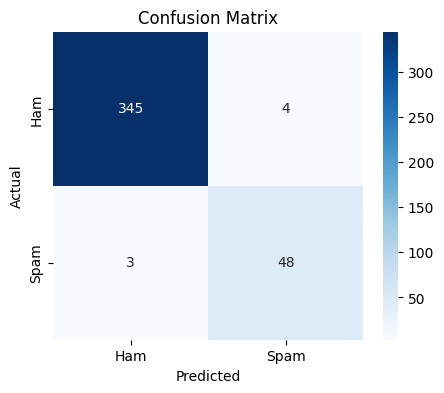

In [14]:
y_prob = model.predict(X_test)
y_pred = (y_prob > 0.5).astype(int).ravel()

print("Accuracy  :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall    :", round(recall_score(y_test, y_pred), 4))
print("F1-score  :", round(f1_score(y_test, y_pred), 4))
print("\n", classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix')
plt.show()

In [15]:
def predict_sms(msg):
    seq = tokenizer.texts_to_sequences([clean_text(msg)])
    pad = pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')
    p = model.predict(pad, verbose=0)[0][0]
    return ("SPAM" if p > 0.5 else "HAM"), round(float(p), 3)

new_msgs = [
    "Congratulations! You have won a free iPhone. Click http://claim-now.com to collect your prize",
    "URGENT! Your account is blocked. Call 09061234567 now to claim 1000 cash",
    "Hey, are we meeting at the canteen after class?",
    "Please send me the DL notes before tomorrow",
    "WINNER!! You have been selected for a 500 reward. Text CLAIM to 80082",
    "Amma said dinner ready, come fast"
]

for m in new_msgs:
    label, prob = predict_sms(m)
    print(f"[{label}] (spam prob = {prob})  ->  {m}\n")

[SPAM] (spam prob = 0.993)  ->  Congratulations! You have won a free iPhone. Click http://claim-now.com to collect your prize

[SPAM] (spam prob = 0.993)  ->  URGENT! Your account is blocked. Call 09061234567 now to claim 1000 cash

[HAM] (spam prob = 0.0)  ->  Hey, are we meeting at the canteen after class?

[HAM] (spam prob = 0.002)  ->  Please send me the DL notes before tomorrow

[SPAM] (spam prob = 0.993)  ->  WINNER!! You have been selected for a 500 reward. Text CLAIM to 80082

[HAM] (spam prob = 0.0)  ->  Amma said dinner ready, come fast

